In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
booking_requests_df = pd.read_csv("../cleaned_data/booking_requests.csv")
cleaners_df = pd.read_csv("../cleaned_data/cleaners.csv")
customers_df = pd.read_csv("../cleaned_data/customers.csv")
marketing_spend_df = pd.read_csv("../cleaned_data/marketing_spend.csv")

In [3]:
print('Raw rows:', { 'customers': len(customers_df), 'cleaners': len(cleaners_df),
                     'bookings': len(booking_requests_df), 'spend': len(marketing_spend_df)})

Raw rows: {'customers': 24632, 'cleaners': 1511, 'bookings': 132164, 'spend': 243}


## 1. Data preparation

In [4]:
for df, col in [(booking_requests_df,'request_date'), (customers_df,'signup_date'),
                (cleaners_df,'application_date'), (marketing_spend_df,'month')]:
    df[col] = pd.to_datetime(df[col], errors='coerce')
customers_df['cohort'] = customers_df['signup_date'].dt.to_period('M').astype(str)
cleaners_df['cohort'] = cleaners_df['application_date'].dt.to_period('M').astype(str)
booking_requests_df['booking_month'] = booking_requests_df['request_date'].dt.to_period('M')

Only fulfilled bookings generate revenue. Also Kozy earns 20% of the €27 per hour, so it earns €5.40 per fulfilled hour.

In [5]:
fulfilled = booking_requests_df[booking_requests_df['status'].eq('fulfilled')].copy()

fulfilled['hours'] = pd.to_numeric(fulfilled['hours'], errors='coerce')
fulfilled = fulfilled[fulfilled['hours'] > 0].copy()
fulfilled['kozy_revenue'] = fulfilled['hours'] * 5.40

print('Valid fulfilled bookings:', len(fulfilled))
print('Kozy observed revenue: €{:,.2f}'.format(fulfilled['kozy_revenue'].sum()))

Valid fulfilled bookings: 108692
Kozy observed revenue: €1,585,936.80


## 2. Customer acquisition cost (CAC)
**CAC = demand marketing spend / new customers.** 

### Customer CAC by acquisition channel

,customers,spend_eur,CAC
acquisition_channel,,,
Google Ads,8589,205420.0,23.92
Meta Ads,7362,138060.0,18.75


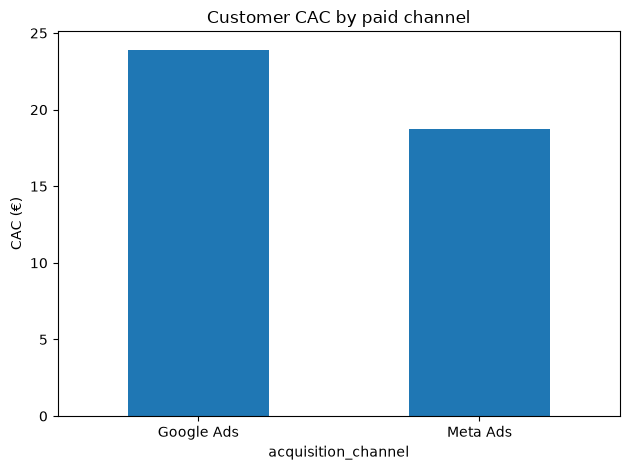

In [8]:
new_customers = (customers_df.groupby(['cohort','city','acquisition_channel'])
                 .agg(customers=('customer_id','nunique')).reset_index())
demand_spend = marketing_spend_df[marketing_spend_df['side'].eq('demand')].copy()
demand_spend['cohort'] = demand_spend['month'].dt.to_period('M').astype(str)
demand_spend = (demand_spend.groupby(['cohort','city','channel'], as_index=False)['spend_eur'].sum())
customer_results = new_customers.merge(demand_spend,
    left_on=['cohort','city','acquisition_channel'],
    right_on=['cohort','city','channel'], how='left')
customer_results['CAC'] = customer_results['spend_eur'] / customer_results['customers']
paid = customer_results[customer_results['acquisition_channel'].isin(['Google Ads','Meta Ads'])].copy()
channel_cac = paid.groupby('acquisition_channel')[['customers','spend_eur']].sum()
channel_cac['CAC'] = channel_cac['spend_eur']/channel_cac['customers']
display(channel_cac.round(2))
channel_cac['CAC'].plot.bar(title='Customer CAC by paid channel', ylabel='CAC (€)', rot=0)
plt.tight_layout(); plt.show()

There is no CAC value for `Referral` and `Organic` channel because Kozy didn't spend money on them.

Meta Ads has a lower customer acquisition cost (€18.75) than Google Ads (€23.92). This means Meta Ads has cheaper acquisition. 

### Customer CAC by city and channel

customers  spend_eur    CAC
city     acquisition_channel                             
Bordeaux Google Ads                1028    24420.0  23.75
         Meta Ads                   856    16100.0  18.81
Lille    Google Ads                 686    16760.0  24.43
         Meta Ads                   560    10580.0  18.89
Lyon     Google Ads                2721    65470.0  24.06
         Meta Ads                  2406    45270.0  18.82
Paris    Google Ads                4154    98770.0  23.78
         Meta Ads                  3540    66110.0  18.68

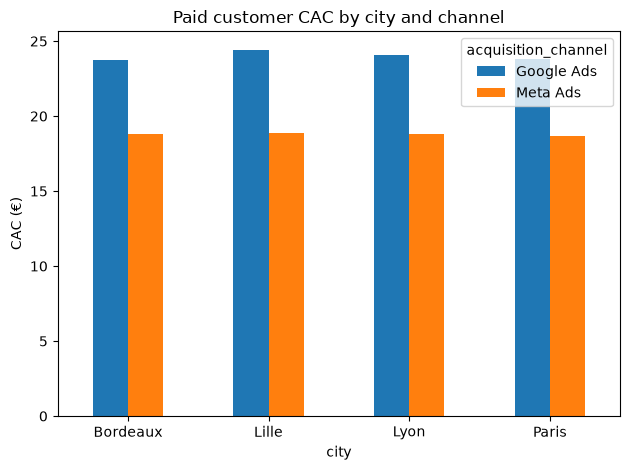

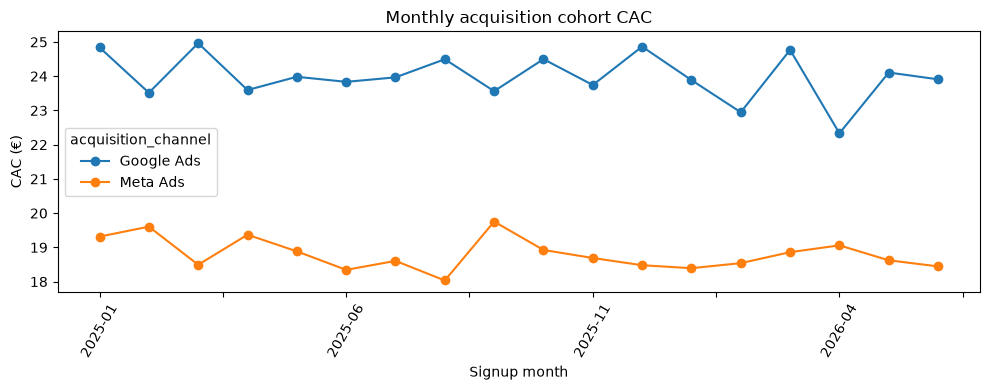

In [9]:
city_channel = paid.groupby(['city','acquisition_channel'])[['customers','spend_eur']].sum()
city_channel['CAC'] = city_channel['spend_eur']/city_channel['customers']
display(city_channel.round(2))
city_channel['CAC'].unstack().plot.bar(title='Paid customer CAC by city and channel', ylabel='CAC (€)', rot=0)
plt.tight_layout(); plt.show()

cohort_cac = paid.groupby(['cohort','acquisition_channel'])[['customers','spend_eur']].sum()
cohort_cac['CAC'] = cohort_cac['spend_eur']/cohort_cac['customers']
cohort_cac['CAC'].unstack().plot(marker='o', figsize=(10,4), title='Monthly acquisition cohort CAC')
plt.ylabel('CAC (€)'); plt.xlabel('Signup month'); plt.xticks(rotation=60); plt.tight_layout(); plt.show()

In all cities and all months CAC for Meta Ads is lower than Google Ads. So, Meta Ads is the more efficient paid channel for customer acquisition.

## 3. Six-month retention and observed LTV
Use 2025 signup cohorts only, so all customers have at least six calendar months observable by 30 June 2026. Month 0 is the signup calendar month; months 0–5 form the six-month window. Customers with no fulfilled bookings remain in the denominator.

,acquisition_channel,customers,revenue,LTV_6m,repeat_rate,CAC,LTV_CAC
0,Google Ads,4628,292777.2,63.26,0.65,23.92,2.65
1,Meta Ads,3954,251780.4,63.68,0.65,18.75,3.40
2,Organic,3326,209050.2,62.85,0.63,NaN,NaN
3,Referral,1368,86362.2,63.13,0.64,NaN,NaN


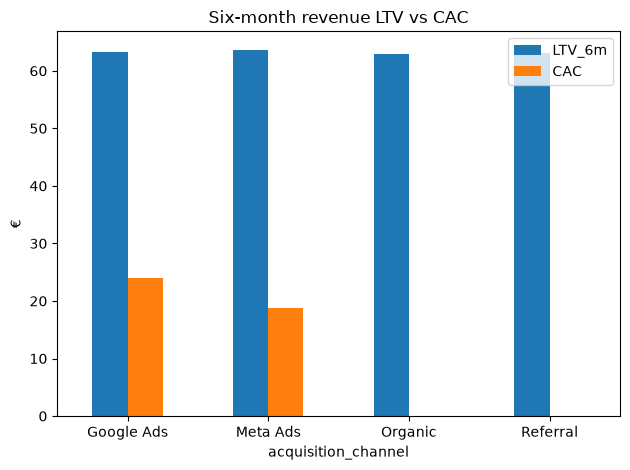

In [10]:
customer_bookings = fulfilled.merge(customers_df[['customer_id','signup_date','cohort','city','acquisition_channel']],
                                      on='customer_id', how='inner', suffixes=('_booking',''))

customer_bookings['age_month'] = ((customer_bookings['request_date'].dt.year-customer_bookings['signup_date'].dt.year)*12
                                 +customer_bookings['request_date'].dt.month-customer_bookings['signup_date'].dt.month)

customer_bookings = customer_bookings[customer_bookings['age_month'].between(0,5)].copy()

cohorts_2025 = customers_df[customers_df['signup_date'].dt.year.eq(2025)].copy()

activity = customer_bookings.groupby('customer_id').agg(bookings=('request_id','nunique'),
                                                        revenue=('kozy_revenue','sum')).reset_index()

customer_data = cohorts_2025.merge(activity,on='customer_id',how='left')

customer_data[['bookings','revenue']] = customer_data[['bookings','revenue']].fillna(0)

customer_data['repeat'] = customer_data['bookings'] >= 2

customer_economics = customer_data.groupby(['city','acquisition_channel']).agg(
    customers=('customer_id','nunique'), repeat_rate=('repeat','mean'), revenue=('revenue','sum')).reset_index()

customer_economics['LTV_6m'] = customer_economics['revenue']/customer_economics['customers']

spend_2025 = paid[paid['cohort'].str.startswith('2025')].groupby(['city','acquisition_channel'])[['spend_eur','customers']].sum().reset_index()

spend_2025['CAC'] = spend_2025['spend_eur']/spend_2025['customers']

customer_economics = customer_economics.merge(spend_2025[['city','acquisition_channel','CAC']],
                                               on=['city','acquisition_channel'],how='left')

customer_economics['LTV_CAC'] = customer_economics['LTV_6m']/customer_economics['CAC']

channel_economics = customer_economics.groupby('acquisition_channel').agg(
    customers=('customers','sum'), revenue=('revenue','sum')).reset_index()

channel_economics['LTV_6m'] = channel_economics['revenue']/channel_economics['customers']

repeat_by_channel = customer_data.groupby('acquisition_channel')['repeat'].mean()

channel_economics['repeat_rate'] = channel_economics['acquisition_channel'].map(repeat_by_channel)

channel_economics = channel_economics.merge(channel_cac[['CAC']].reset_index(),on='acquisition_channel',how='left')

channel_economics['LTV_CAC'] = channel_economics['LTV_6m']/channel_economics['CAC']

display(channel_economics.round(2))
channel_economics.set_index('acquisition_channel')[['LTV_6m','CAC']].plot.bar(title='Six-month revenue LTV vs CAC',ylabel='€',rot=0)
plt.tight_layout(); plt.show()

Monthly cohort retention: share of all signups who booked at least once in that age month

age_month,0,1,2,3,4,5
cohort,,,,,,
2025-01,68.2,49.4,38.6,34.2,31.0,25.9
2025-02,79.2,50.4,39.5,37.6,33.7,28.8
2025-03,67.4,45.3,40.2,36.0,28.8,25.8
2025-04,73.8,49.6,42.2,35.3,31.6,26.6
2025-05,77.1,54.2,45.3,38.4,31.8,28.3
2025-06,81.0,54.9,45.2,37.0,33.4,30.2
2025-07,81.6,56.4,46.4,38.2,32.9,30.2
2025-08,76.8,53.2,44.2,37.5,31.7,27.8
2025-09,76.6,50.9,43.7,35.9,33.1,28.1


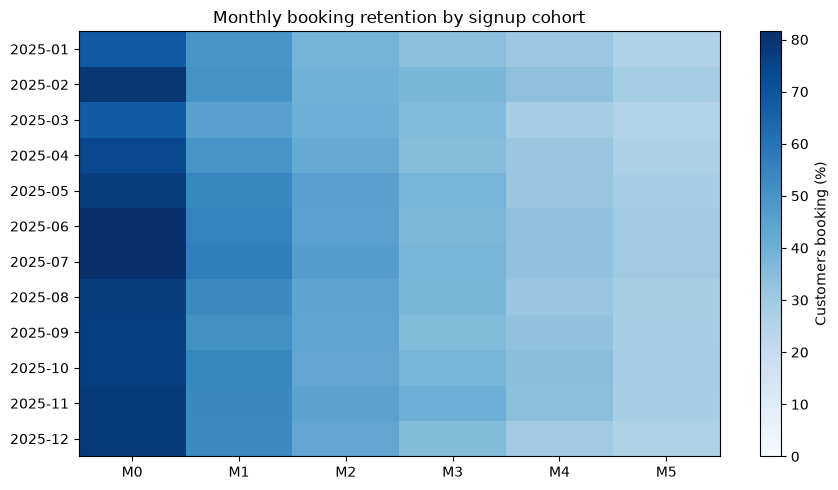

In [ ]:
monthly_active = customer_bookings[['customer_id','cohort','age_month']].drop_duplicates()

monthly_counts = monthly_active.groupby(['cohort','age_month'])['customer_id'].nunique().unstack(fill_value=0)

cohort_sizes = cohorts_2025.groupby('cohort')['customer_id'].nunique()

retention = monthly_counts.reindex(cohort_sizes.index, fill_value=0).reindex(columns=range(6),fill_value=0)

retention = retention.div(cohort_sizes,axis=0)

display((retention*100).round(1))
plt.figure(figsize=(9,5))
plt.imshow(retention*100,aspect='auto',cmap='Blues',vmin=0)
plt.colorbar(label='Customers booking (%)')
plt.xticks(range(6),[f'M{i}' for i in range(6)])
plt.yticks(range(len(retention)),retention.index)
plt.title('Monthly booking retention by signup cohort')
plt.tight_layout();plt.show()

Customer retention decreases over time for every cohort. Around 68–82% of customers book in their signup month, but only around 26–30% book in month five. This shows that keeping customers active is an important challenge.

## 4. Revenue payback

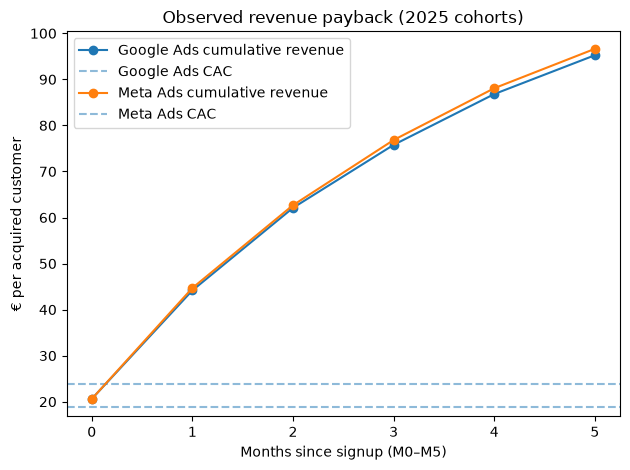

Google Ads 2025 CAC €24.16, first observed payback month: M1
Meta Ads 2025 CAC €18.84, first observed payback month: M0


In [ ]:
paid_2025 = cohorts_2025[cohorts_2025['acquisition_channel'].isin(['Google Ads','Meta Ads'])]
monthly_revenue = customer_bookings.groupby(['acquisition_channel','age_month'])['kozy_revenue'].sum().unstack(fill_value=0)
paid_sizes = paid_2025.groupby('acquisition_channel')['customer_id'].nunique()
monthly_revenue = monthly_revenue.reindex(paid_sizes.index,fill_value=0).reindex(columns=range(6),fill_value=0)
cumulative = monthly_revenue.div(paid_sizes,axis=0).cumsum(axis=1)

for channel in cumulative.index:
    plt.plot(range(6),cumulative.loc[channel],marker='o',label=channel+' cumulative revenue')
    if channel in channel_cac.index:
        plt.axhline(channel_cac.loc[channel,'CAC'],linestyle='--',alpha=.5,label=channel+' CAC')

plt.xticks(range(6));plt.xlabel('Months since signup (M0–M5)');plt.ylabel('€ per acquired customer')
plt.title('Observed revenue payback (2025 cohorts)');plt.legend();plt.tight_layout();plt.show()

for channel in cumulative.index:
    cac = spend_2025.loc[spend_2025['acquisition_channel'].eq(channel),'spend_eur'].sum() / paid_sizes[channel]
    reached = cumulative.loc[channel][cumulative.loc[channel] >= cac]
    print(channel, '2025 CAC €{:.2f}, first observed payback month: {}'.format(cac, 'M'+str(reached.index[0]) if len(reached) else 'not reached by M5'))

Meta Ads recovers its acquisition cost in month 0, while Google Ads reaches payback in month 1. This means Meta Ads generates enough platform revenue to recover its acquisition spending sooner.

## 5. Cleaner acquisition (supply side)

Stakeholders must choose between customer marketing and cleaner recruitment. We will compare cost per applicant, cost per onboarded cleaner, and cost per productive cleaner (at least one fulfilled job).

,applicants,onboarded,productive_cleaners,spend_eur,Cost_per_applicant,Cost_per_onboarded,Cost_per_productive
acquisition_channel,,,,,,,
Job boards,818,606,593,68440.0,83.67,112.94,115.41
Meta Ads,488,355,343,34280.0,70.25,96.56,99.94
Referral,205,140,134,0.0,0.00,0.00,0.00


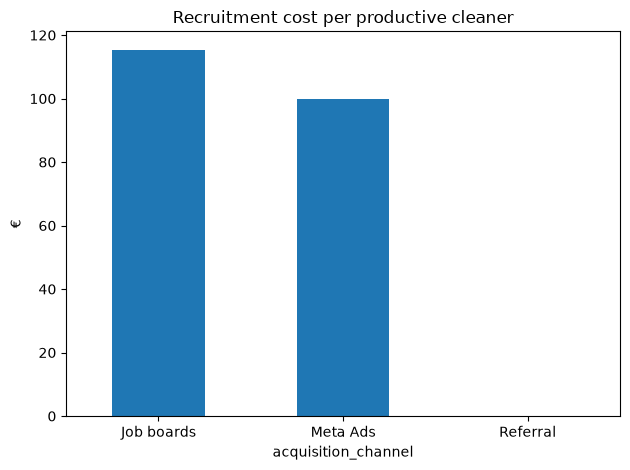

In [13]:
productive_ids = set(fulfilled['cleaner_id'].dropna())

cleaners_df['productive'] = cleaners_df['cleaner_id'].isin(productive_ids)
cleaners_df['onboarded'] = cleaners_df['onboarded_date'].notna()
cleaner_counts = cleaners_df.groupby(['cohort','city','acquisition_channel']).agg(
    applicants=('cleaner_id','nunique'), onboarded=('onboarded','sum'),
    productive_cleaners=('productive','sum')).reset_index()

supply_spend = marketing_spend_df[marketing_spend_df['side'].eq('supply')].copy()
supply_spend['cohort'] = pd.to_datetime(supply_spend['month']).dt.to_period('M').astype(str)
supply_spend = supply_spend.groupby(['cohort','city','channel'],as_index=False)['spend_eur'].sum()
cleaner_results = cleaner_counts.merge(supply_spend,left_on=['cohort','city','acquisition_channel'],
                                      right_on=['cohort','city','channel'],how='left')

cleaner_channel = cleaner_results.groupby('acquisition_channel')[['applicants','onboarded','productive_cleaners','spend_eur']].sum()

for label,denom in [('Cost_per_applicant','applicants'),('Cost_per_onboarded','onboarded'),('Cost_per_productive','productive_cleaners')]:
    cleaner_channel[label] = cleaner_channel['spend_eur']/cleaner_channel[denom].replace(0,np.nan)
display(cleaner_channel.round(2))

cleaner_channel['Cost_per_productive'].dropna().plot.bar(title='Recruitment cost per productive cleaner',ylabel='€',rot=0)
plt.tight_layout();plt.show()

Cost per productive cleaner is more meaningful than cost per application because only productive cleaners create value.

Meta Ads has a lower cost per productive cleaner (€99.94) than Job Boards (€115.41). Referral has no recorded acquisition spending and brings 134 productive cleaners, making it an attractive recruitment channel.

applicants  onboarded  productive_cleaners  \
city     acquisition_channel                                               
Bordeaux Job boards                  128         95                   92   
         Meta Ads                    298        220                  214   
         Referral                     50         35                   34   
Lille    Job boards                   91         71                   69   
         Meta Ads                     37         31                   29   
         Referral                     18         12                   12   
Lyon     Job boards                  130         95                   93   
         Meta Ads                     38         24                   22   
         Referral                     17         12                   10   
Paris    Job boards                  469        345                  339   
         Meta Ads                    115         80                   78   
         Referral                    120         81                   78   

                              spend_eur     CAC  
city     acquisition_channel                     
Bordeaux Job boards             10870.0  114.42  
         Meta Ads               20890.0   94.95  
         Referral                   0.0    0.00  
Lille    Job boards              7550.0  106.34  
         Meta Ads                2580.0   83.23  
         Referral                   0.0    0.00  
Lyon     Job boards             10660.0  112.21  
         Meta Ads                2670.0  111.25  
         Referral                   0.0    0.00  
Paris    Job boards             39360.0  114.09  
         Meta Ads                8140.0  101.75  
         Referral                   0.0    0.00

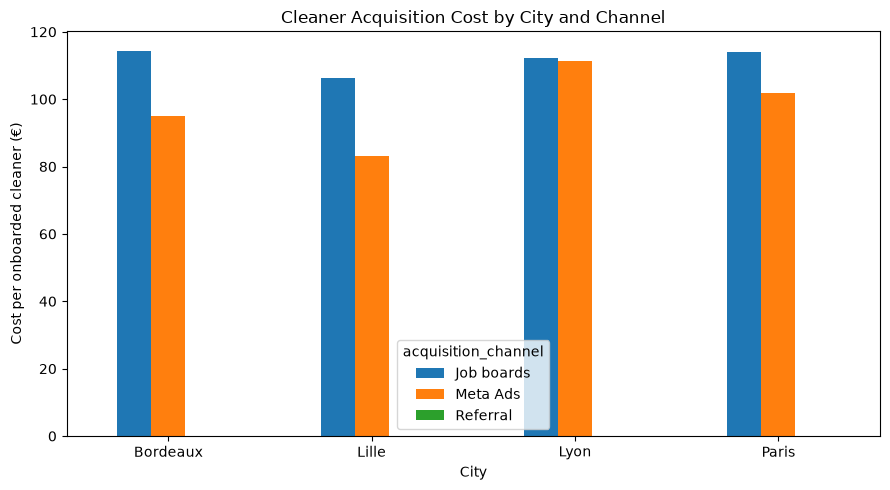

In [ ]:
cleaner_city_channel = cleaner_results.groupby(
    ['city', 'acquisition_channel']
)[['applicants', 'onboarded', 'productive_cleaners', 'spend_eur']].sum()

cleaner_city_channel['CAC'] = (
    cleaner_city_channel['spend_eur'] /
    cleaner_city_channel['onboarded'].replace(0, np.nan)
)

display(cleaner_city_channel.round(2))

# Plot
cleaner_city_channel['CAC'].unstack().plot(
    kind='bar', figsize=(9, 5)
)

plt.title('Cleaner Acquisition Cost by City and Channel')
plt.ylabel('Cost per onboarded cleaner (€)')
plt.xlabel('City')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In the table, CAC means cost per onboarded cleaner, because onboarded cleaners are eligible to accept jobs.

The cost of onboarding cleaners differs between cities and recruitment channels. Meta Ads is particularly cost-efficient in Bordeaux, while Job Boards remain an important source of cleaners in other cities.

In [15]:
cleaner_city = cleaner_results.groupby('city')[
    ['onboarded', 'spend_eur']
].sum()

cleaner_city['CAC'] = (
    cleaner_city['spend_eur'] /
    cleaner_city['onboarded'].replace(0, np.nan)
)

display(cleaner_city.round(2))

,onboarded,spend_eur,CAC
city,,,
Bordeaux,350,31760.0,90.74
Lille,114,10130.0,88.86
Lyon,131,13330.0,101.76
Paris,506,47500.0,93.87


Lille has the lowest average cost per onboarded cleaner (€88.86), followed by Bordeaux (€90.74), Paris (€93.87), and Lyon (€101.76). Lyon is the most expensive city for cleaner onboarding.